In [10]:
# Resolve inputs from the repository root or any folder inside it.
from pathlib import Path
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/featureengineering.py").is_file()), None)
assert REPO is not None, "Open/run this notebook from within the project folder"
MAIN_CSV = REPO / "data/processed/BeijingHousingPrices_featured.csv"
RAW_XLSX = REPO / "data/raw/BeijingHousingPrices.xlsx"
YEARBOOK_DIR = REPO / "notebooks/yearbook"
GEOJSON = YEARBOOK_DIR / "beijing_districts.geojson"
OUT = REPO / "outputs/beijing_a3_visualisations"
for p in [MAIN_CSV, RAW_XLSX, YEARBOOK_DIR / "manifest.json", GEOJSON]:
    assert p.exists(), f"Missing input: {p}. See README.md for data preparation."


In [11]:
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.dates import AutoDateLocator, DateFormatter
from matplotlib.ticker import FixedLocator, NullLocator
from matplotlib.transforms import Bbox, blended_transform_factory
from shapely import STRtree
from shapely.geometry import Point, box, shape
from shapely.ops import unary_union

sys.path.insert(0, str(REPO / "src"))
import bt2102_style as bs
import importlib
importlib.reload(bs)  # Pick up palette edits when Run All reuses an existing kernel.

sys.path.insert(0, str(REPO / "src"))
from featureengineering import CENTER_LAT, CENTER_LNG   # the point distance_to_center_km is measured from

bs.setup()
OUT.mkdir(parents=True, exist_ok=True)
SRC = "Lianjia transactions, 2012-2017"
BASE, END = 2012, 2017
YEARS = list(range(BASE, END + 1))
N_YRS = END - BASE
CENTRE = (CENTER_LNG, CENTER_LAT)
INDEX_BASE = 2015                      # P2a: index base year, the last year before the 2016-17 boom
POLICY = pd.Timestamp("2017-03-17")   # Beijing "3.17" purchase curbs (higher down payments, shorter loans)
MIN_DISTRICT_TRADES = 100              # minimum sales at each endpoint of the district comparison period
pd.set_option("display.width", 160)


def publish(fig, name, source):
    """Add the source line, shrink any text that runs off the figure, keep the axes clear of the title block and
    the source line, then save to OUT and show the live figure."""
    src_t = fig.text(0.04, 0.025, f"Source: {source}", fontsize=10, color=bs.MUTED, va="bottom")
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    for t in fig.texts:
        while t.get_window_extent(r).x1 > fig.bbox.width * 0.985 and t.get_fontsize() > 8:
            t.set_fontsize(t.get_fontsize() - 0.5)
    H, gap = fig.bbox.height, 6
    for _ in range(3):
        fig.canvas.draw()
        boxes = [a.get_tightbbox(r) for a in fig.axes]
        head = [t.get_window_extent(r).y0 for t in fig.texts if t.get_position()[1] >= 0.8]
        d_top = max(0, max(b.y1 for b in boxes) - (min(head) - gap)) / H if head else 0
        d_bot = max(0, src_t.get_window_extent(r).y1 + gap - min(b.y0 for b in boxes)) / H
        if d_top < 1e-3 and d_bot < 1e-3:
            break
        for a in fig.axes:
            p = a.get_position()
            a.set_position([p.x0, p.y0 + d_bot, p.width, max(p.height - d_bot - d_top, 0.05)])
    fig.savefig(OUT / name, dpi=bs.DPI)
    display(fig)
    plt.close(fig)


def place_labels(ax, xs, ys, labels, styles=None, size=150, fontsize=11.5):
    """Label scatter points without overlaps: try right, left, above, below and the diagonals, keep the first
    spot that clears every point, every existing text and the legend, and stays inside the axes."""
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    rad = np.sqrt(size) / 2 * fig.dpi / 72 + 2
    taken = [Bbox.from_extents(px - rad, py - rad, px + rad, py + rad)
             for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    taken += [t.get_window_extent(r) for t in ax.texts]
    if ax.get_legend():
        taken.append(ax.get_legend().get_window_extent(r))
    frame = ax.get_window_extent(r)
    cands = [(9, 0, "left", "center"), (-9, 0, "right", "center"), (0, 10, "center", "bottom"), (0, -10, "center", "top"),
             (8, 8, "left", "bottom"), (8, -8, "left", "top"), (-8, 8, "right", "bottom"), (-8, -8, "right", "top"),
             (14, 14, "left", "bottom"), (14, -14, "left", "top"), (-14, 14, "right", "bottom"), (-14, -14, "right", "top")]
    styles = styles or [{}] * len(labels)
    for x, y, lab, st in zip(xs, ys, labels, styles):
        for k, (dx, dy, ha, va) in enumerate(cands + [cands[0]]):
            t = ax.annotate(lab, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                            fontsize=st.get("fontsize", fontsize), color=st.get("color", bs.INK),
                            fontweight=st.get("fontweight", "normal"), bbox=st.get("bbox"), zorder=7)
            bb = t.get_window_extent(r)
            inside = frame.x0 <= bb.x0 and bb.x1 <= frame.x1 and frame.y0 <= bb.y0 and bb.y1 <= frame.y1
            if k == len(cands) or (inside and not any(bb.overlaps(o) for o in taken)):
                taken.append(bb)
                break
            t.remove()


def padded(lo, hi, frac=0.08, include=()):
    """Axis limits around the data (and any reference values), with a margin."""
    lo, hi = min([lo, *include]), max([hi, *include])
    pad = (hi - lo) * frac or 1
    return lo - pad, hi + pad


def join_names(xs):
    xs = list(xs)
    return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]


def year_ranges(years):
    runs = []
    for y in sorted(years):
        if runs and y == runs[-1][1] + 1:
            runs[-1][1] = y
        else:
            runs.append([y, y])
    return join_names([f"{a}" if a == b else f"{a}–{str(b)[-2:]}" for a, b in runs])


def phrase(lab):
    """Category label as it reads mid-sentence: '<50 m²' and '0–5 km' stay, 'Top floor' -> 'top floor'."""
    return lab if lab[0].isdigit() or lab[0] in "<>" else lab[0].lower() + lab[1:]

In [12]:
df = pd.read_csv(MAIN_CSV, low_memory=False)
raw = pd.read_excel(RAW_XLSX, usecols=["id", "DOM"])   # DOM was dropped from the featured file
df["id"] = df["id"].astype(str)
raw["id"] = raw["id"].astype(str)
assert not raw.id.duplicated().any()
df = df.drop(columns="DOM", errors="ignore").merge(raw, on="id", how="left", validate="many_to_one")
n_all = len(df)

df = df[df.trade_year.between(BASE, END) & (df.ladderRatio <= 1)].copy()
df["date"] = pd.to_datetime(df.tradeTime)
df["ym"] = df.date.dt.to_period("M")
df["quarter"] = df.date.dt.to_period("Q")

BANDS = ["0–5 km", "5–10 km", "10–15 km", "15–20 km", "20–30 km", "30+ km"]
SIZE_MAP = {"<50": "<50 m²", "50-90": "50–90 m²", "90-140": "90–140 m²", "140+": "140+ m²"}
AGE_MAP = {"0-5": "0–5 yrs", "6-15": "6–15 yrs", "16-30": "16–30 yrs", "30+": "30+ yrs"}
BTYPES = ["Plate", "Plate + tower", "Tower"]
df["band"] = pd.cut(df.distance_to_center_km, [0, 5, 10, 15, 20, 30, 100], labels=BANDS)
df["btype"] = df.buildingType.map({1: "Tower", 3: "Plate + tower", 4: "Plate"})
df["subway_lab"] = df.subway.map({1: "Near subway", 0: "No subway"})
df["elev_lab"] = df.elevator.map({1: "Has elevator", 0: "No elevator"})
df["size_lab"] = df.size_category.map(SIZE_MAP)
df["age_lab"] = df.age_bucket.map(AGE_MAP)
df["floor_lab"] = df.story_type.map({"Low": "Low floor", "Middle": "Middle floor", "High": "High floor", "Top": "Top floor"})
SIZE_ORDER, AGE_ORDER = list(SIZE_MAP.values()), list(AGE_MAP.values())

# Rule 4: DOM is recorded properly from the month after the last month whose median DOM is still 1 day
dom_m = df.groupby("ym").DOM.median()
low = dom_m[dom_m <= 1].index
DOM_START = low.max() + 1 if len(low) else dom_m.dropna().index.min()
assert DOM_START <= pd.Period(f"{END}-01", "M"), "DOM charts need a full END year of DOM data"
DOM_START_TS = DOM_START.to_timestamp()   # same month, as a timestamp for formatting

print(f"{n_all:,} rows in {MAIN_CSV.name}; {len(df):,} after filters ({BASE}–{END}, ladderRatio ≤ 1); "
      f"{df.DOM.notna().mean():.0%} with DOM")
print(f"Rule 4: DOM recorded properly from {DOM_START_TS:%b %Y}")
print("Rule 5: median followers by year:", df.groupby("trade_year").followers.median().to_dict())

297,490 rows in BeijingHousingPrices_featured.csv; 290,653 after filters (2012–2017, ladderRatio ≤ 1); 52% with DOM
Rule 4: DOM recorded properly from Jun 2016
Rule 5: median followers by year: {2012: 0.0, 2013: 1.0, 2014: 3.0, 2015: 5.0, 2016: 14.0, 2017: 31.0}


In [13]:
EN = {"110101": "Dongcheng", "110103": "Dongcheng", "110102": "Xicheng", "110104": "Xicheng",
      "110105": "Chaoyang", "110106": "Fengtai", "110107": "Shijingshan", "110108": "Haidian",
      "110109": "Mentougou", "110111": "Fangshan", "110112": "Tongzhou", "110113": "Shunyi",
      "110114": "Changping", "110115": "Daxing", "110116": "Huairou", "110117": "Pinggu",
      "110228": "Miyun", "110229": "Yanqing", "110118": "Miyun", "110119": "Yanqing"}
gj = json.load(open(GEOJSON, encoding="utf-8"))
polys = {}
for f in gj["features"]:
    nm = EN[str(f["properties"]["id"])]
    polys[nm] = unary_union([polys[nm], shape(f["geometry"])]) if nm in polys else shape(f["geometry"])
names = list(polys)
tree = STRtree([polys[n] for n in names])
hit = tree.query([Point(x, y) for x, y in zip(df.Lng, df.Lat)], predicate="within")
df["boundary"] = "outside"
df.iloc[hit[0], df.columns.get_loc("boundary")] = [names[i] for i in hit[1]]
check = pd.crosstab(df.district, df.boundary)
check["share_in_top"] = check.max(axis=1) / check.sum(axis=1)
check["top_boundary"] = check.drop(columns="share_in_top").idxmax(axis=1)

import featureengineering
importlib.reload(featureengineering)
from featureengineering import DISTRICT_MAP
DISTRICT = DISTRICT_MAP.copy()
check["notebook_name"] = check.index.map(DISTRICT)
check["featured_csv_name"] = df.groupby("district").district_name.agg(lambda s: s.mode().iat[0])
print(check[["top_boundary", "share_in_top", "notebook_name", "featured_csv_name"]].round(3))
for code, row in check.iterrows():
    allowed = {DISTRICT[code]}
    if row.top_boundary not in allowed:
        import warnings
        warnings.warn(f"Approximate basemap mismatch for code {code}: notebook label {DISTRICT[code]}, most points in {row.top_boundary}. Original labels retained; boundary/coordinate alignment requires review.")
df["dname"] = df.district.map(DISTRICT)

boundary top_boundary  share_in_top notebook_name featured_csv_name
district                                                           
1           Dongcheng         0.611     Dongcheng         Dongcheng
2             Fengtai         0.777       Fengtai           Fengtai
3              Daxing         0.885      Tongzhou          Tongzhou
4              Daxing         0.915        Daxing            Daxing
5            Fangshan         1.000      Fangshan          Fangshan
6           Changping         0.989     Changping         Changping
7            Chaoyang         0.984      Chaoyang          Chaoyang
8             Haidian         0.859       Haidian           Haidian
9         Shijingshan         0.944   Shijingshan       Shijingshan
10            Xicheng         0.855       Xicheng           Xicheng
11           Tongzhou         1.000        Pinggu            Pinggu
12          Mentougou         0.704     Mentougou         Mentougou
13             Shunyi         0.950        Shuny

/var/folders/hd/rg1pd_9n27l1j1s6_8hcl6rm0000gn/T/ipykernel_11548/846144373.py:31: UserWarning: Approximate basemap mismatch for code 3: notebook label Tongzhou, most points in Daxing. Original labels retained; boundary/coordinate alignment requires review.
  warnings.warn(f"Approximate basemap mismatch for code {code}: notebook label {DISTRICT[code]}, most points in {row.top_boundary}. Original labels retained; boundary/coordinate alignment requires review.")
/var/folders/hd/rg1pd_9n27l1j1s6_8hcl6rm0000gn/T/ipykernel_11548/846144373.py:31: UserWarning: Approximate basemap mismatch for code 11: notebook label Pinggu, most points in Tongzhou. Original labels retained; boundary/coordinate alignment requires review.
  warnings.warn(f"Approximate basemap mismatch for code {code}: notebook label {DISTRICT[code]}, most points in {row.top_boundary}. Original labels retained; boundary/coordinate alignment requires review.")


In [14]:
manifest = json.load(open(YEARBOOK_DIR / "manifest.json", encoding="utf-8"))
for m in manifest:
    ok = hashlib.sha256(open(YEARBOOK_DIR / m["raw_path"], "rb").read()).hexdigest() == m["sha256"]
    print(f"{m['table_id']:>5}  {m['title_en']:<55} hash ok: {ok}")
    assert ok

CN = {"全市": "Beijing", "东城区": "Dongcheng", "西城区": "Xicheng", "朝阳区": "Chaoyang", "丰台区": "Fengtai",
      "石景山区": "Shijingshan", "海淀区": "Haidian", "门头沟区": "Mentougou", "房山区": "Fangshan",
      "通州区": "Tongzhou", "顺义区": "Shunyi", "昌平区": "Changping", "大兴区": "Daxing", "怀柔区": "Huairou",
      "平谷区": "Pinggu", "密云区": "Miyun", "延庆区": "Yanqing", "北京经济技术开发区": "Yizhuang"}


def yearbook(path):
    t = pd.read_csv(path, skiprows=2, encoding="utf-8-sig")
    t = t[t.iloc[:, 0].isin(CN)].copy()
    t.index = t.iloc[:, 0].map(CN)
    return t.iloc[:, 1:].apply(pd.to_numeric)


pop = yearbook(YEARBOOK_DIR / "district_resident_population_2-1.csv")
income = yearbook(YEARBOOK_DIR / "district_per_capita_disposable_income_2-14.csv")
supply = yearbook(YEARBOOK_DIR / "district_commercial_housing_3-20.csv")
LIANJIA = set(df.dname)
supply

FileNotFoundError: [Errno 2] No such file or directory: '/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/notebooks/yearbook/district_resident_population_2-1.csv'

In [13]:
DISTRICT_BASE, DISTRICT_END = 2015, 2017
DISTRICT_YEARS = list(range(DISTRICT_BASE, DISTRICT_END + 1))
DISTRICT_N_YRS = DISTRICT_END - DISTRICT_BASE
DISTRICT_SRC = f"Lianjia recorded sales, {DISTRICT_BASE}–{DISTRICT_END}"
district_df = df[df.trade_year.between(DISTRICT_BASE, DISTRICT_END)].copy()
dist_year = district_df.groupby(["dname", "trade_year"]).price.median().unstack().reindex(columns=DISTRICT_YEARS)
dist_n = district_df.groupby(["dname", "trade_year"]).size().unstack().reindex(columns=DISTRICT_YEARS, fill_value=0)
print(dist_n)
valid = dist_n[[DISTRICT_BASE, DISTRICT_END]].ge(MIN_DISTRICT_TRADES).all(axis=1)
EXCLUDED = list(valid[~valid].index)
dcagr = ((dist_year[DISTRICT_END] / dist_year[DISTRICT_BASE]) ** (1 / DISTRICT_N_YRS) - 1)[valid].sort_values() * 100
district_benchmark = dcagr.median()  # equal district weights, consistent with PD4
assert len(dcagr) == 13 and "Fangshan" in dcagr.index
print(f"excluded (<{MIN_DISTRICT_TRADES} sales in {DISTRICT_BASE} or {DISTRICT_END}):", EXCLUDED)
EXCL_TXT = f"{join_names(EXCLUDED)} excluded (too few endpoint sales)" if EXCLUDED else "All 13 districts have at least 100 endpoint sales"


trade_year    2015   2016   2017
dname                           
Changping     7095  11553   5508
Chaoyang     21953  29684  14244
Daxing        2772   4170   2160
Dongcheng     3995   4352   2195
Fangshan       437   1448    730
Fengtai       5564   7968   3918
Haidian       7913   9398   4673
Mentougou      280    464    259
Pinggu        2817   2440   1652
Shijingshan   2000   2831   1356
Shunyi        1805   2170   1089
Tongzhou       373    922    348
Xicheng       7051   7615   3776
excluded (<100 sales in 2015 or 2017): []


size_lab   <50 m²  50–90 m²  90–140 m²  140+ m²
age_lab                                        
0–5 yrs       212      1496        852      181
6–15 yrs     1968      8059       6652     1630
16–30 yrs    2464     10682       2655      678
30+ yrs      1059      3272         46        2


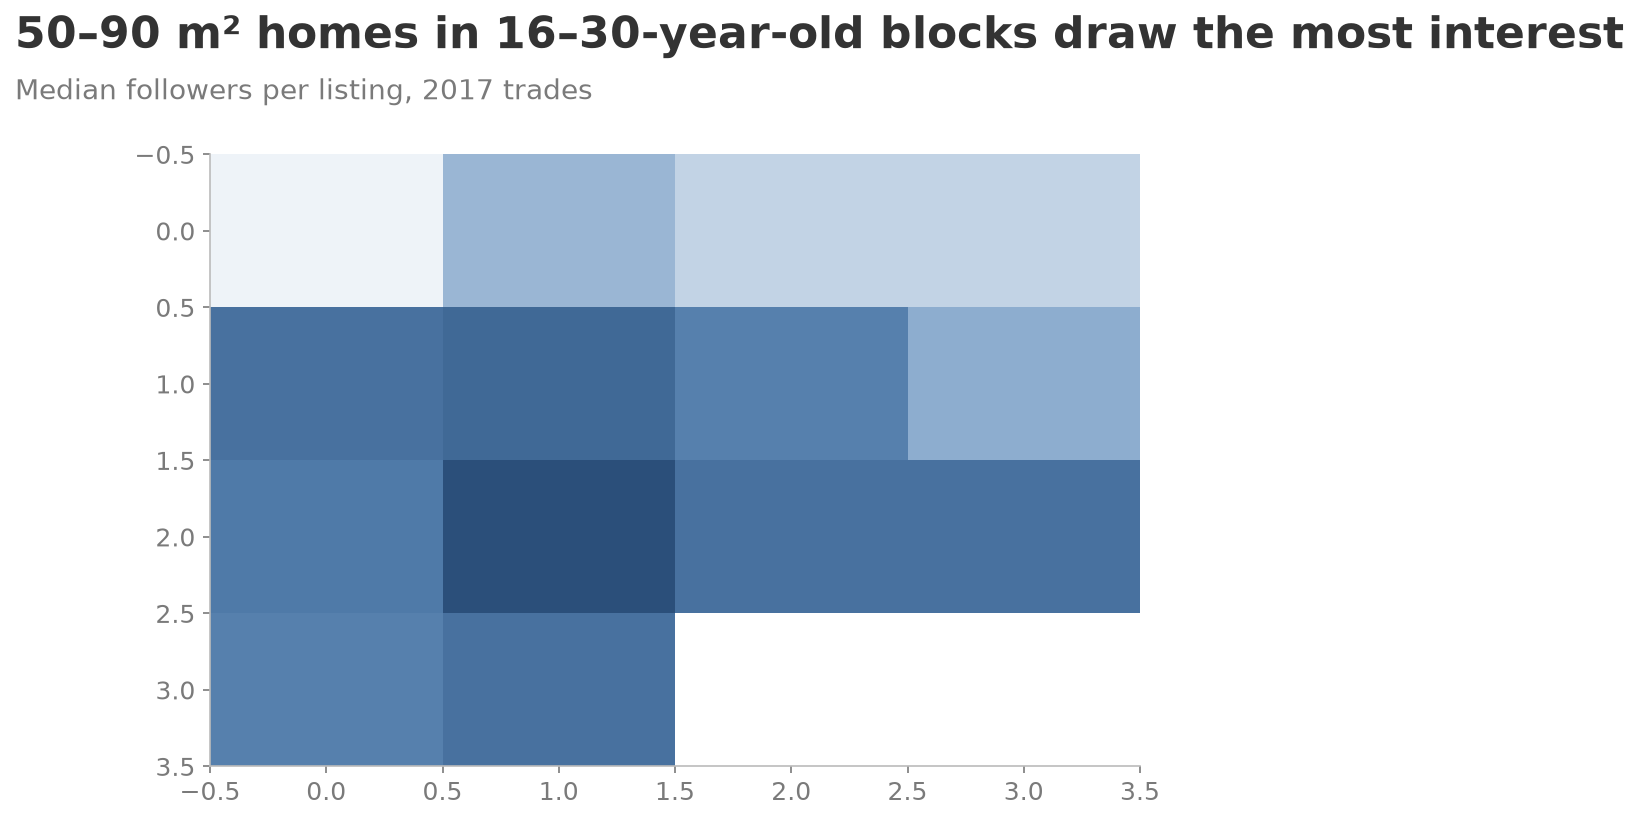

In [17]:
d17 = df[df.trade_year == END]
fol = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="median").loc[AGE_ORDER, SIZE_ORDER]
cnt = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="size").loc[AGE_ORDER, SIZE_ORDER]
fol = fol.where(cnt >= 100)
print(cnt)
best = fol.stack().idxmax()
fig, ax = bs.new_chart(f"{best[1]} homes in {best[0].replace(' yrs', '')}-year-old blocks draw the most interest",
                       f"Median followers per listing, {END} trades", rect=(0.17, 0.12, 0.62, 0.68))
cmap = LinearSegmentedColormap.from_list("b", ["#EEF3F8"] + bs.SEQ_BLUES[1:])
im = ax.imshow(fol.values, cmap=cmap, aspect="auto")


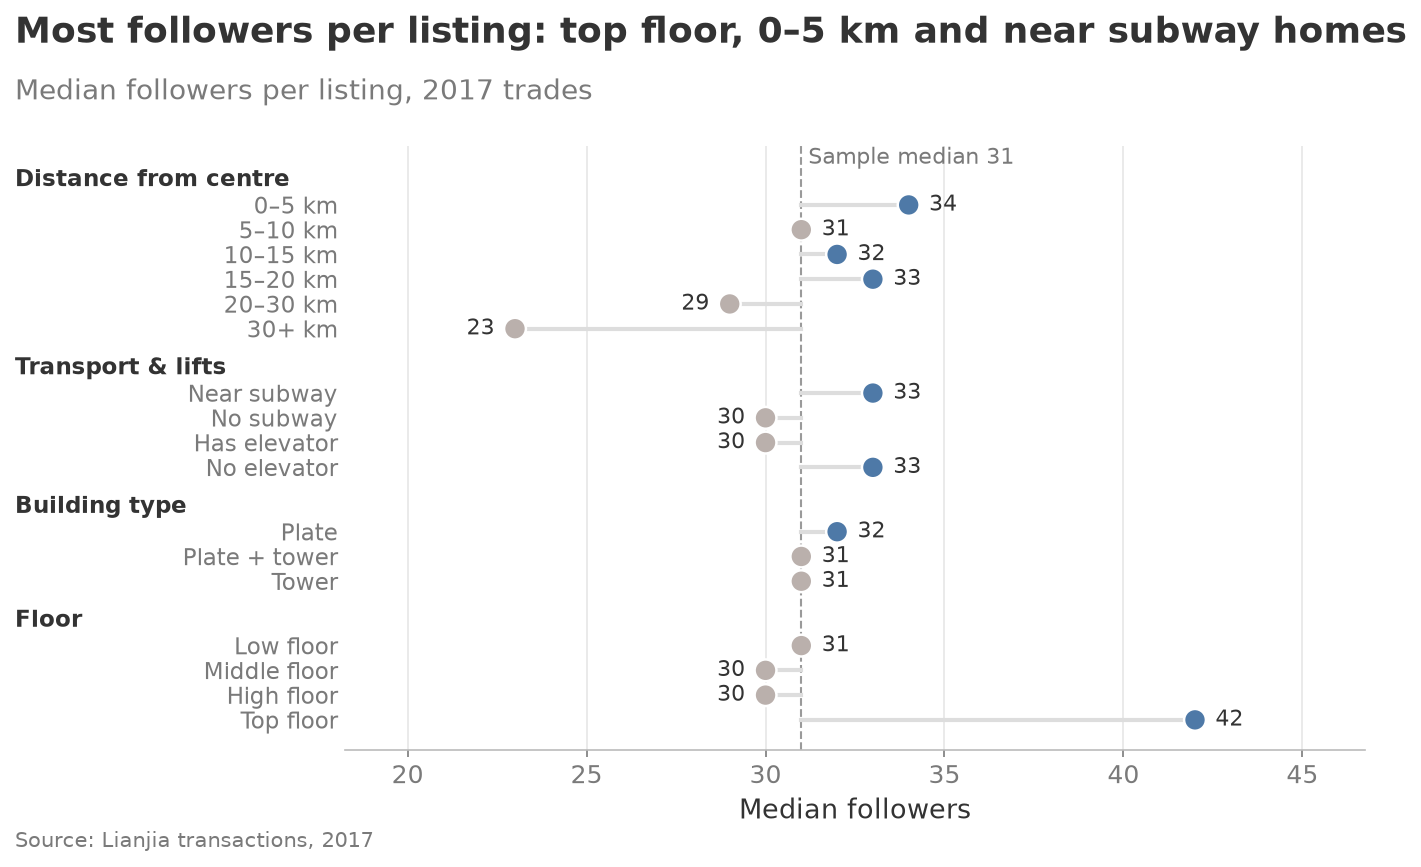

In [18]:
def grouped_dots(groups, values, title, subtitle, xlabel, name, ref=None, ref_label=None, fmt="{:.0f}",
                 src=SRC, colour_rule=None):
    """Horizontal dot plot with grouped categories. groups = [(header, [labels])], values = dict label->value."""
    rows, heads, y = [], [], 0
    for head, labs in groups:
        heads.append((y, head))
        y += 1
        for lab in labs:
            rows.append((y, lab, values[lab]))
            y += 1
        y += 0.6
    fig, ax = bs.new_chart(title, subtitle, rect=(0.26, 0.13, 0.68, 0.68))
    ys, labs, vals = zip(*rows)
    vals = np.array(vals)
    cols = [colour_rule(v) if colour_rule else bs.HIGHLIGHT for v in vals]
    if ref is not None:
        ax.axvline(ref, color="#9A9A9A", lw=1, ls="--", zorder=1)
        ax.text(ref, -0.9, f" {ref_label}", fontsize=10.5, color=bs.MUTED, va="center")
        for yy, v in zip(ys, vals):
            ax.plot([ref, v], [yy, yy], color="#DDDDDD", lw=2, zorder=1)
    ax.scatter(vals, ys, s=110, color=cols, zorder=3, edgecolor="white", lw=1.2)
    lo, hi = padded(vals.min(), vals.max(), 0.25, include=[ref] if ref is not None else [])
    span = hi - lo
    for yy, v, c in zip(ys, vals, cols):
        right = ref is None or v >= ref
        ax.text(v + (span * 0.02 if right else -span * 0.02), yy, fmt.format(v), va="center",
                ha="left" if right else "right", fontsize=10.5, color=bs.INK)
    ax.set_yticks(ys, labs)
    tr = blended_transform_factory(fig.transFigure, ax.transData)
    for yh, head in heads:
        ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
    ax.tick_params(axis="y", length=0, labelsize=11)
    ax.spines["left"].set_visible(False)
    ax.set_ylim(y - 0.4, -1.4)
    ax.set_xlim(lo, hi)
    ax.set_xlabel(xlabel)
    bs.xgrid(ax)
    publish(fig, name, src)


GROUPS_CHAR = [("Distance from centre", BANDS),
               ("Transport & lifts", ["Near subway", "No subway", "Has elevator", "No elevator"]),
               ("Building type", BTYPES),
               ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]
vals = {}
for col in ["band", "subway_lab", "elev_lab", "btype", "floor_lab"]:
    vals.update(d17.groupby(col, observed=True).followers.median().to_dict())
med17 = d17.followers.median()
group_best = sorted(((vals[max(labs, key=vals.get)], max(labs, key=vals.get)) for _, labs in GROUPS_CHAR), reverse=True)
top = [phrase(lab) for v, lab in group_best[:3] if v > med17]
grouped_dots(GROUPS_CHAR, vals, f"Most followers per listing: {join_names(top)} homes" if top else
             "No characteristic lifts followers above the typical home",
             f"Median followers per listing, {END} trades", "Median followers", "D5_followers_by_characteristic.png",
             ref=med17, ref_label=f"Sample median {med17:.0f}",
             colour_rule=lambda v: bs.HIGHLIGHT if v > med17 else bs.CONTEXT,
             src=f"Lianjia transactions, {END}")

Shared supported change endpoints: ['2015Q3', '2015Q4', '2016Q1', '2016Q2', '2016Q3', '2016Q4', '2017Q1', '2017Q4']


,volatility_pp,available_changes,used_changes
dname,,,
Haidian,5.892257,11,8
Tongzhou,7.889218,11,8
Fengtai,8.908937,11,8
Xicheng,6.016258,11,8
Chaoyang,7.325997,11,8
Shijingshan,9.631730,11,8
Changping,8.254621,11,8
Dongcheng,6.670004,11,8
Daxing,8.947837,11,8


age-band volatility spread 2.64 pp -> shown


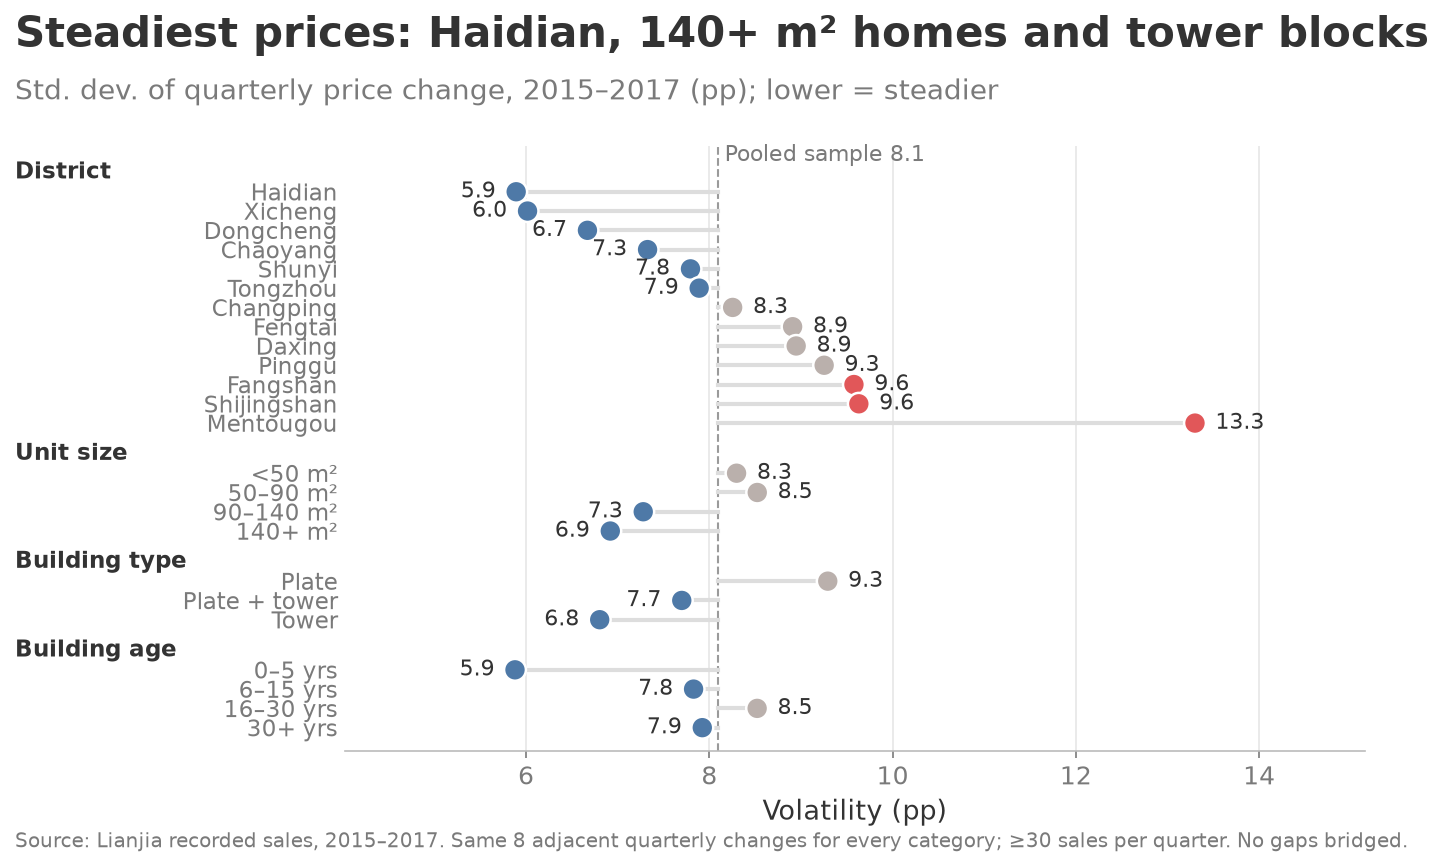

            group       category  volatility_pp                status
1        District        Haidian           5.89  Steadier than pooled
3        District        Xicheng           6.02  Steadier than pooled
5        District      Dongcheng           6.67  Steadier than pooled
7        District       Chaoyang           7.33  Steadier than pooled
9        District         Shunyi           7.79  Steadier than pooled
11       District       Tongzhou           7.89  Steadier than pooled
13       District      Changping           8.25           Near pooled
15       District        Fengtai           8.91           Near pooled
17       District         Daxing           8.95           Near pooled
19       District         Pinggu           9.25           Near pooled
21       District       Fangshan           9.58    Much more volatile
23       District    Shijingshan           9.63    Much more volatile
25       District      Mentougou          13.30    Much more volatile
27      Unit size   

In [23]:
VOL_QUARTERS = pd.period_range(f"{DISTRICT_BASE}Q1", f"{DISTRICT_END}Q4", freq="Q")
quarter_counts = district_df.groupby(["dname", "quarter"]).size().unstack().reindex(index=dcagr.index, columns=VOL_QUARTERS)
quarter_ok = quarter_counts.ge(30)
adjacent_ok = quarter_ok & quarter_ok.shift(1, axis=1, fill_value=False)
# Compare identical quarterly changes across all districts, without bridging gaps.
COMMON_CHANGES = adjacent_ok.columns[adjacent_ok.all(axis=0)]
assert len(COMMON_CHANGES) == 8
print("Shared supported change endpoints:", [str(q) for q in COMMON_CHANGES])

def volatility_stats(col, data=district_df, min_n=30):
    q = data.groupby([col, "quarter"], observed=True).price.agg(["median", "size"])
    medians = q["median"].where(q["size"] >= min_n).unstack().reindex(columns=VOL_QUARTERS)
    changes = medians.pct_change(axis=1, fill_method=None) * 100
    common = changes.reindex(columns=COMMON_CHANGES)
    stats = pd.DataFrame({"volatility_pp": common.std(axis=1),
                          "available_changes": changes.count(axis=1), "used_changes": common.count(axis=1)})
    stats.loc[stats.used_changes != len(COMMON_CHANGES), "volatility_pp"] = np.nan
    return stats

def volatility(col):
    return volatility_stats(col).volatility_pp.dropna()

vol_support = volatility_stats("dname").reindex(dcagr.index)
vol_d = vol_support.volatility_pp.dropna()
assert len(vol_d) == 13 and vol_support.used_changes.eq(8).all()
display(vol_support)
vol_vals = {}
for col in ["size_lab", "btype", "age_lab"]:
    vol_vals.update(volatility(col).to_dict())
vol_vals.update(vol_d.to_dict())
city_vol = district_df.groupby("quarter").price.median().reindex(VOL_QUARTERS).pct_change(fill_method=None).reindex(COMMON_CHANGES).std() * 100
vol_groups = [("District", list(vol_d.sort_values().index)), ("Unit size", SIZE_ORDER), ("Building type", BTYPES)]
age_spread = max(vol_vals[a] for a in AGE_ORDER) - min(vol_vals[a] for a in AGE_ORDER)
if age_spread >= 0.5:
    vol_groups.append(("Building age", AGE_ORDER))
print(f"age-band volatility spread {age_spread:.2f} pp -> {'shown' if age_spread >= 0.5 else 'left out (bands are near-identical)'}")
steady = {head: min(labs, key=vol_vals.get) for head, labs in vol_groups}
grouped_dots(vol_groups, vol_vals,
             f"Steadiest prices: {steady['District']}, {steady['Unit size']} homes and {phrase(steady['Building type'])} blocks",
             f"Std. dev. of quarterly price change, {DISTRICT_BASE}–{DISTRICT_END} (pp); lower = steadier",
             "Volatility (pp)", "R1_price_volatility.png", ref=city_vol, ref_label=f"Pooled sample {city_vol:.1f}",
             fmt="{:.1f}", colour_rule=lambda v: bs.NEGATIVE if v > city_vol * 1.15 else (bs.HIGHLIGHT if v < city_vol else bs.CONTEXT),
             src=DISTRICT_SRC + ". Same 8 adjacent quarterly changes for every category; ≥30 sales per quarter. No gaps bridged.")

rows = []
order = 0
for g_i, (group, labels) in enumerate(vol_groups):
    for lab in labels:
        v = vol_vals[lab]
        status = ("Much more volatile" if v > city_vol * 1.15
                  else "Steadier than pooled" if v < city_vol
                  else "Near pooled")
        for point, val in [("Pooled", city_vol), ("Category", v)]:
            rows.append({"group": group, "group_order": g_i, "category": lab,
                         "sort_order": order, "point": point,
                         "volatility_pp": round(val, 2), "status": status,
                         "pooled_vol_pp": round(city_vol, 2)})
        order += 1
OUT_DIR = Path("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/Visualisations/qn 5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

vol_tidy = pd.DataFrame(rows)
vol_tidy.to_csv(OUT_DIR / "risk_volatility_dots.csv", index=False)
print(vol_tidy.query("point == 'Category'")[["group", "category", "volatility_pp", "status"]])



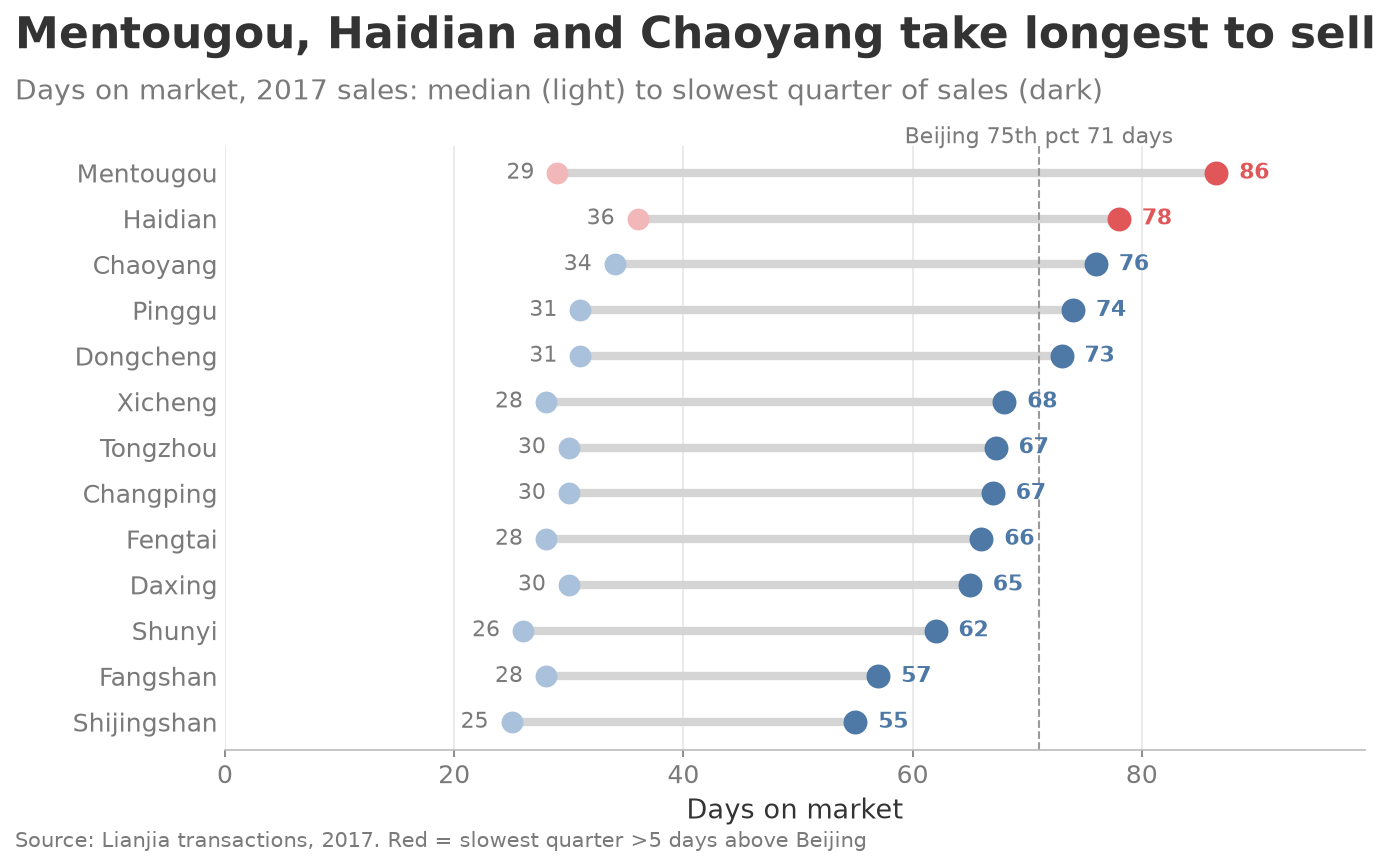

Title: Mentougou, Haidian and Chaoyang take longest to sell
Beijing 75th percentile: 71 days
              med    p75      n
dname                          
Mentougou    29.0  86.50    259
Haidian      36.0  78.00   4673
Chaoyang     34.0  76.00  14244
Pinggu       31.0  74.00   1652
Dongcheng    31.0  73.00   2195
Xicheng      28.0  68.00   3776
Tongzhou     30.0  67.25    348
Changping    30.0  67.00   5508
Fengtai      28.0  66.00   3918
Daxing       30.0  65.00   2160
Shunyi       26.0  62.00   1089
Fangshan     28.0  57.00    730
Shijingshan  25.0  55.00   1356


In [15]:
d17d = df[(df.trade_year == END) & df.DOM.notna()]


def dom_stats(col):
    return d17d.groupby(col, observed=True).DOM.agg(med="median", p75=lambda s: s.quantile(0.75), n="size")


dd = dom_stats("dname").sort_values("p75")
city_p75 = d17d.DOM.quantile(0.75)
fig, ax = bs.new_chart(f"{join_names(list(dd.index[::-1][:3]))} take longest to sell",
                       f"Days on market, {END} sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.18, 0.13, 0.76, 0.68))
for i, (d_, r) in enumerate(dd.iterrows()):
    risky = r.p75 > city_p75 + 5
    c = bs.NEGATIVE if risky else bs.HIGHLIGHT
    ax.plot([r.med, r.p75], [i, i], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(r.med, i, s=90, color="#A9C1DB" if not risky else "#F2B8B9", zorder=3)
    ax.scatter(r.p75, i, s=110, color=c, zorder=3)
    ax.text(r.p75 + 2, i, f"{r.p75:.0f}", va="center", fontsize=10.5, color=c, fontweight="bold")
    ax.text(r.med - 2, i, f"{r.med:.0f}", va="center", ha="right", fontsize=10.5, color=bs.MUTED)
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, len(dd) - 0.35, f"Beijing 75th pct {city_p75:.0f} days", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_yticks(range(len(dd)), dd.index)
ax.set_xlim(0, dd.p75.max() * 1.15)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
publish(fig, "R2_dom_by_district.png", f"Lianjia transactions, {END}. Red = slowest quarter >5 days above Beijing")


OUT_DIR = Path("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/Visualisations/qn 5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

dd = dom_stats("dname").sort_values("p75")
city_p75 = d17d.DOM.quantile(0.75)

rows = []
for d_, r in dd.iterrows():
    risk = "Higher risk" if r.p75 > city_p75 + 5 else "Lower risk"
    for stat, val in [("Median", r.med), ("75th pct", r.p75)]:
        rows.append({"district": d_, "statistic": stat, "dom_days": round(val, 1),
                     "risk_status": risk, "dot_key": f"{risk} – {stat}",
                     "n_trades": int(r.n), "city_p75": round(city_p75, 1)})

dom_tidy = pd.DataFrame(rows)
dom_tidy.to_csv(OUT_DIR / "dom_by_district_2017.csv", index=False)

print("Title:", f"{join_names(list(dd.index[::-1][:3]))} take longest to sell")
print(f"Beijing 75th percentile: {city_p75:.0f} days")
print(dd.sort_values("p75", ascending=False))

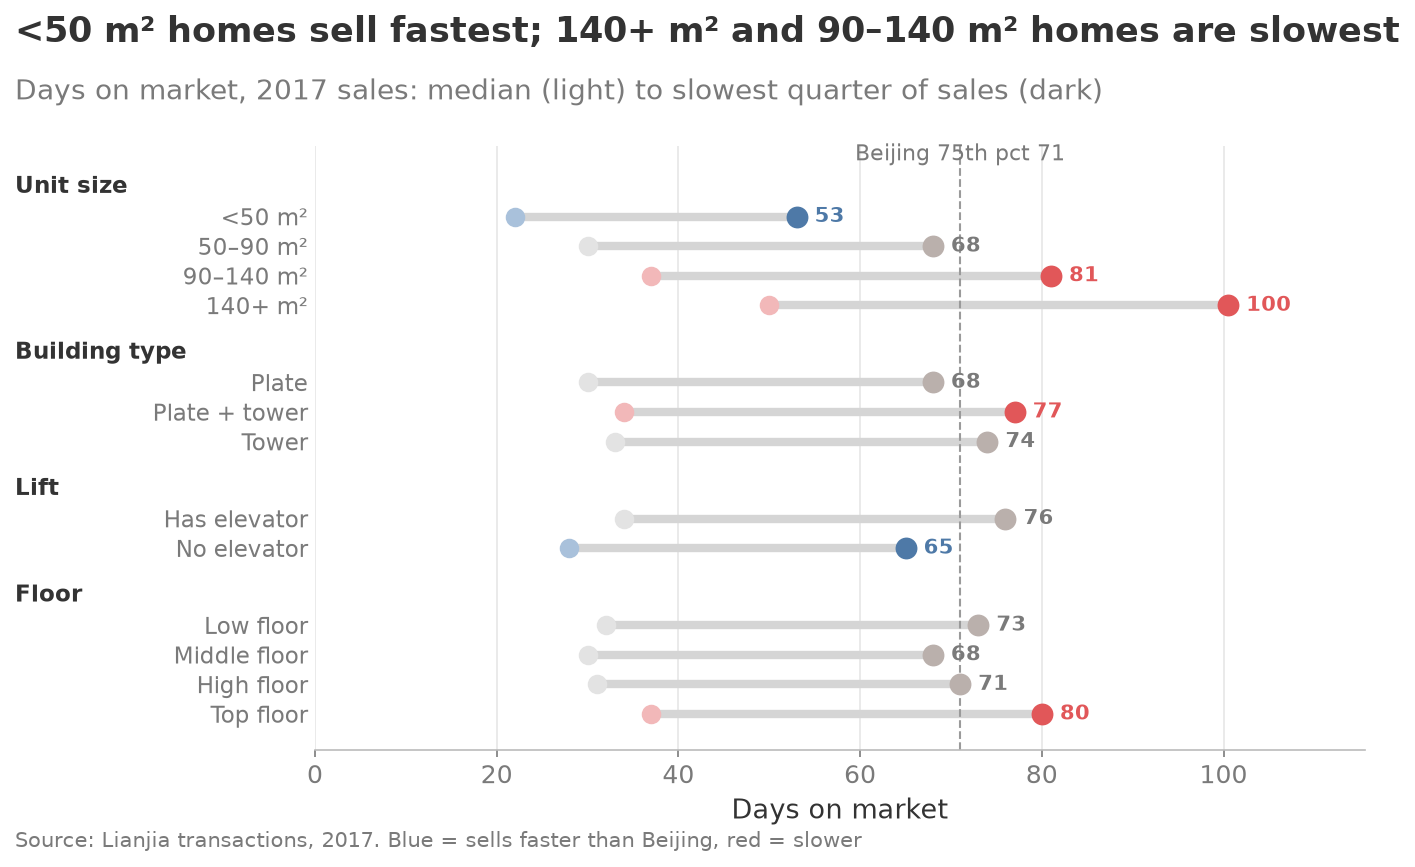

Title: <50 m² homes sell fastest; 140+ m² and 90–140 m² homes are slowest
Beijing 75th percentile: 71 days
        group      category  dom_days  n_trades               status
    Unit size        <50 m²      53.0      5703  Faster than Beijing
    Unit size      50–90 m²      68.0     23509 In line with Beijing
    Unit size     90–140 m²      81.0     10205  Slower than Beijing
    Unit size       140+ m²     100.5      2491  Slower than Beijing
Building type         Plate      68.0     23576 In line with Beijing
Building type Plate + tower      77.0      7946  Slower than Beijing
Building type         Tower      74.0     10385 In line with Beijing
         Lift  Has elevator      76.0     23942 In line with Beijing
         Lift   No elevator      65.0     17966  Faster than Beijing
        Floor     Low floor      73.0     11898 In line with Beijing
        Floor  Middle floor      68.0     16223 In line with Beijing
        Floor    High floor      71.0      9165 In line with Beij

In [16]:
seg_groups = [("Unit size", SIZE_ORDER), ("Building type", BTYPES),
              ("Lift", ["Has elevator", "No elevator"]),
              ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]   # age and subway: see checks table
seg = pd.concat([dom_stats(c) for c in ["size_lab", "age_lab", "btype", "subway_lab", "elev_lab", "floor_lab"]])
rows, heads, yc = [], [], 0
for head, labs in seg_groups:
    heads.append((yc, head)); yc += 1
    for lab in labs:
        rows.append((yc, lab, seg.loc[lab, "med"], seg.loc[lab, "p75"])); yc += 1
    yc += 0.6
shown = pd.Series({lab: p75 for _, lab, _, p75 in rows}).sort_values()
fig, ax = bs.new_chart(f"{shown.index[0]} homes sell fastest; {join_names([phrase(l) for l in shown.index[::-1][:2]])} "
                       "homes are slowest",
                       f"Days on market, {END} sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.24, 0.13, 0.70, 0.68))
for yy, lab, med, p75 in rows:
    risky, fast_ = p75 > city_p75 + 5, p75 < city_p75 - 5
    c = bs.NEGATIVE if risky else (bs.HIGHLIGHT if fast_ else bs.CONTEXT)
    ax.plot([med, p75], [yy, yy], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(med, yy, s=70, color="#E3E3E3" if c == bs.CONTEXT else ("#F2B8B9" if risky else "#A9C1DB"), zorder=3)
    ax.scatter(p75, yy, s=90, color=c, zorder=3)
    ax.text(p75 + 2, yy, f"{p75:.0f}", va="center", fontsize=10, color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold")
ax.set_yticks([r[0] for r in rows], [r[1] for r in rows])
tr = blended_transform_factory(fig.transFigure, ax.transData)
for yh, head in heads:
    ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, -0.9, f"Beijing 75th pct {city_p75:.0f}", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_ylim(yc - 0.4, -1.4)
ax.set_xlim(0, shown.max() * 1.15)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
publish(fig, "R3_dom_by_segment.png", f"Lianjia transactions, {END}. Blue = sells faster than Beijing, red = slower")

from pathlib import Path

OUT_DIR = Path("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/Visualisations/qn 5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

rows_out, sort_order = [], 0
for g_i, (head, labs) in enumerate(seg_groups):
    for lab in labs:
        med, p75, n = seg.loc[lab, "med"], seg.loc[lab, "p75"], int(seg.loc[lab, "n"])
        if p75 > city_p75 + 5:
            status = "Slower than Beijing"
        elif p75 < city_p75 - 5:
            status = "Faster than Beijing"
        else:
            status = "In line with Beijing"
        for stat, val in [("Median", med), ("75th pct", p75)]:
            rows_out.append({"group": head, "group_order": g_i, "category": lab,
                             "sort_order": sort_order, "statistic": stat,
                             "dom_days": round(val, 1), "status": status,
                             "dot_key": f"{status} - {stat}",
                             "n_trades": n, "city_p75": round(city_p75, 1)})
        sort_order += 1

seg_tidy = pd.DataFrame(rows_out)
seg_tidy.to_csv(OUT_DIR / "dom_by_segment_2017.csv", index=False)

print("Title:", f"{shown.index[0]} homes sell fastest; {join_names([phrase(l) for l in shown.index[::-1][:2]])} homes are slowest")
print(f"Beijing 75th percentile: {city_p75:.0f} days")
print(seg_tidy.query("statistic == '75th pct'")[["group", "category", "dom_days", "n_trades", "status"]].to_string(index=False))

In [17]:
## For qn 5 part 3 linear regression model
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

OUT_DIR = Path("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/Visualisations/qn 5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Factor name shown on the chart -> column in d17d
FACTORS = {
    "District": "dname",
    "Unit size": "size_lab",
    "Building type": "btype",
    "Lift": "elev_lab",
    "Floor": "floor_lab",
    "Building age": "age_lab",
    "Subway": "subway_lab",
}
MIN_LEVEL_N = 30   # levels with fewer sales are flagged as unreliable in Tableau

# --------------------------------------------------------------------------- #
# Data: 2017 sales with DOM, outcome = slower than Beijing's 75th percentile
# --------------------------------------------------------------------------- #
data = d17d[["DOM"] + list(FACTORS.values())].dropna().copy()
for col in FACTORS.values():
    data[col] = data[col].astype(str)
data["slow"] = (data["DOM"] > city_p75).astype(int)
print(f"Sales used: {len(data):,} of {len(d17d):,} | share slow: {data['slow'].mean():.1%} "
      f"| threshold: DOM > {city_p75:.0f} days")

# --------------------------------------------------------------------------- #
# Dummy variables. Baseline = the most common level of each factor.
# --------------------------------------------------------------------------- #
X_parts, meta, baselines = [], [], {}
for factor, col in FACTORS.items():
    ref = data[col].value_counts().idxmax()
    baselines[factor] = ref
    for lev in sorted(data[col].unique()):
        if lev == ref:
            continue
        name = f"{factor}|{lev}"
        X_parts.append((data[col] == lev).astype(float).rename(name))
        meta.append((factor, col, lev, ref, name))

X = pd.concat(X_parts, axis=1)
Xc = sm.add_constant(X)
model = sm.Logit(data["slow"], Xc).fit(disp=0)
assert model.mle_retvals["converged"], "Model did not converge"
print(f"Pseudo R-squared: {model.prsquared:.3f}")
print("Baselines:", baselines)

# --------------------------------------------------------------------------- #
# Multicollinearity check (flag anything above 5)
# --------------------------------------------------------------------------- #
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns
).sort_values(ascending=False)
print("\nHighest VIFs (look into anything above 5):")
print(vif.head(8).round(1).to_string())

# --------------------------------------------------------------------------- #
# Results table: adjusted odds ratio, 95% CI, raw odds ratio
# --------------------------------------------------------------------------- #
def odds(s):
    p = s.mean()
    return p / (1 - p) if 0 < p < 1 else np.nan

ci = model.conf_int()
rows = []
for factor, col, lev, ref, name in meta:
    sub = data[data[col] == lev]
    base = data[data[col] == ref]
    rows.append({
        "factor": factor, "level": lev, "is_baseline": False,
        "odds_ratio": np.exp(model.params[name]),
        "ci_low": np.exp(ci.loc[name, 0]), "ci_high": np.exp(ci.loc[name, 1]),
        "p_value": model.pvalues[name],
        "raw_odds_ratio": odds(sub["slow"]) / odds(base["slow"]),
        "n_level": len(sub), "slow_rate_pct": sub["slow"].mean() * 100,
    })
for factor, col in FACTORS.items():
    ref = baselines[factor]
    sub = data[data[col] == ref]
    rows.append({
        "factor": factor, "level": ref, "is_baseline": True,
        "odds_ratio": 1.0, "ci_low": 1.0, "ci_high": 1.0, "p_value": np.nan,
        "raw_odds_ratio": 1.0, "n_level": len(sub), "slow_rate_pct": sub["slow"].mean() * 100,
    })

res = pd.DataFrame(rows)
res["effect"] = np.select(
    [res["is_baseline"], res["ci_low"] > 1, res["ci_high"] < 1],
    ["Baseline", "Raises odds of a slow sale", "Lowers odds of a slow sale"],
    default="No clear effect",
)
res["label"] = np.where(res["is_baseline"], res["level"] + " (baseline)", res["level"])
res["reliable"] = res["n_level"] >= MIN_LEVEL_N
res["factor_order"] = res["factor"].map({f: i for i, f in enumerate(FACTORS)})
res = res.sort_values(["factor_order", "odds_ratio"], ascending=[True, False]).reset_index(drop=True)
res["sort_order"] = res.index

# --------------------------------------------------------------------------- #
# Long format for Tableau: three points per row (CI low, estimate, CI high)
# --------------------------------------------------------------------------- #
keep = ["factor", "factor_order", "label", "sort_order", "effect", "reliable",
        "n_level", "slow_rate_pct", "raw_odds_ratio", "p_value"]
long = pd.concat([
    res.assign(point=p, or_value=res[c])[keep + ["point", "or_value"]]
    for p, c in [("CI low", "ci_low"), ("Estimate", "odds_ratio"), ("CI high", "ci_high")]
])
long["or_value"] = long["or_value"].round(3)
long["threshold_days"] = round(city_p75, 1)
long.to_csv(OUT_DIR / "dom_slow_model_2017.csv", index=False)

print("\nAdjusted odds ratios (>1 = more likely to be a slow sale):")
print(res[["factor", "label", "odds_ratio", "ci_low", "ci_high", "raw_odds_ratio", "n_level", "effect"]]
      .round(2).to_string(index=False))

Sales used: 41,906 of 41,908 | share slow: 24.9% | threshold: DOM > 71 days
Pseudo R-squared: 0.017
Baselines: {'District': 'Chaoyang', 'Unit size': '50–90 m²', 'Building type': 'Plate', 'Lift': 'Has elevator', 'Floor': 'Middle floor', 'Building age': '6–15 yrs', 'Subway': 'Near subway'}

Highest VIFs (look into anything above 5):
Lift|No elevator               2.7
Building type|Tower            2.1
Building type|Plate + tower    1.7
Building age|16–30 yrs         1.7
Building age|30+ yrs           1.6
District|Changping             1.4
Floor|Low floor                1.2
Floor|High floor               1.2

Adjusted odds ratios (>1 = more likely to be a slow sale):
       factor                   label  odds_ratio  ci_low  ci_high  raw_odds_ratio  n_level                     effect
     District               Mentougou        1.22    0.93     1.60            1.22      259            No clear effect
     District                 Haidian        1.12    1.04     1.21            1.06     46